In [14]:
%pip install pandas networkx numpy matplotlib scikit-learn gensim openpyxl --quiet


Note: you may need to restart the kernel to use updated packages.


In [15]:
import pandas as pd
import networkx as nx
import numpy as np
import random
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from gensim.models import Word2Vec

In [16]:
# Load the data
df = pd.read_excel("Payments.xlsx")
df.columns = ['source', 'target', 'amount']

In [17]:
 #Node2Vec from scratch
class Node2Vec:
    def __init__(self, graph, dimensions=64, walk_length=10, num_walks=100, window_size=5):
        self.graph = graph
        self.dimensions = dimensions
        self.walk_length = walk_length
        self.num_walks = num_walks
        self.window_size = window_size
        self.node2idx = {node: str(i) for i, node in enumerate(graph.nodes())}
        self.idx2node = {v: k for k, v in self.node2idx.items()}

    def node2vec_walk(self, start_node):
        walk = [start_node]
        for _ in range(self.walk_length - 1):
            cur = walk[-1]
            neighbors = list(self.graph.successors(cur))
            if not neighbors:
                break
            next_node = random.choice(neighbors)
            walk.append(next_node)
        return walk

    def generate_walks(self):
        walks = []
        nodes = list(self.graph.nodes())
        for _ in range(self.num_walks):
            random.shuffle(nodes)
            for node in nodes:
                walks.append(self.node2vec_walk(node))
        return walks

    def learn_embeddings(self, walks):
        walks_idx = [[self.node2idx[n] for n in walk] for walk in walks]
        model = Word2Vec(sentences=walks_idx, vector_size=self.dimensions, window=self.window_size,
                         min_count=0, sg=1, workers=4, epochs=5)
        embeddings = np.zeros((len(self.graph.nodes()), self.dimensions))
        for node in self.graph.nodes():
            embeddings[int(self.node2idx[node])] = model.wv[self.node2idx[node]]
        return embeddings

In [18]:

# Step 1: Create a MultiDiGraph
multi_graph = nx.MultiDiGraph()
for _, row in df.iterrows():
    multi_graph.add_edge(row['source'], row['target'], weight=row['amount'])

In [19]:

# Step 2: Convert to a simple DiGraph with aggregated edge weights
graph = nx.DiGraph()
for u, v, data in multi_graph.edges(data=True):
    if graph.has_edge(u, v):
        graph[u][v]['weight'] += data['weight']
    else:
        graph.add_edge(u, v, weight=data['weight'])

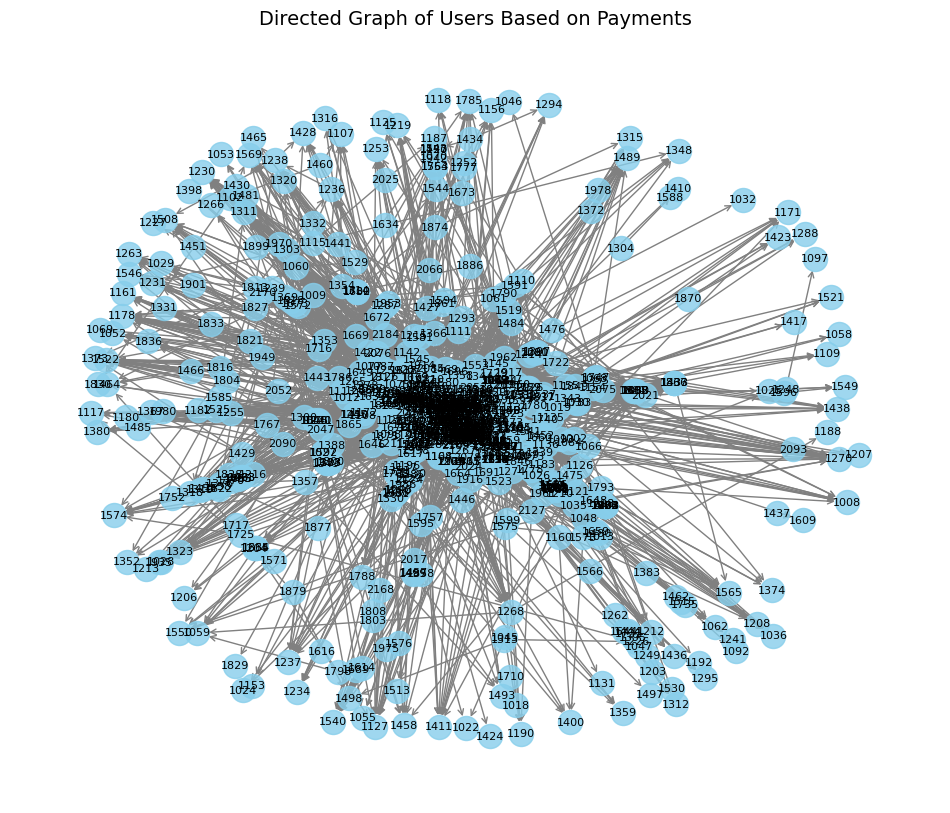

In [20]:

# Step 3: Visualize the directed graph
plt.figure(figsize=(12, 10))
pos = nx.spring_layout(graph, seed=42)
weights = [graph[u][v]['weight'] for u, v in graph.edges()]
nx.draw_networkx_nodes(graph, pos, node_size=300, node_color='skyblue', alpha=0.8)
nx.draw_networkx_edges(graph, pos, edgelist=graph.edges(), arrowstyle='->', arrowsize=10,
                       edge_color='gray', width=1)
nx.draw_networkx_labels(graph, pos, font_size=8)
plt.title("Directed Graph of Users Based on Payments", fontsize=14)
plt.axis('off')
plt.show()

In [21]:
# Step 5: Train node2vec and get embeddings
n2v = Node2Vec(graph, dimensions=64, walk_length=10, num_walks=100, window_size=5)
walks = n2v.generate_walks()
embeddings = n2v.learn_embeddings(walks)

/home/vishnu/miniconda3/envs/fraud_analytics/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


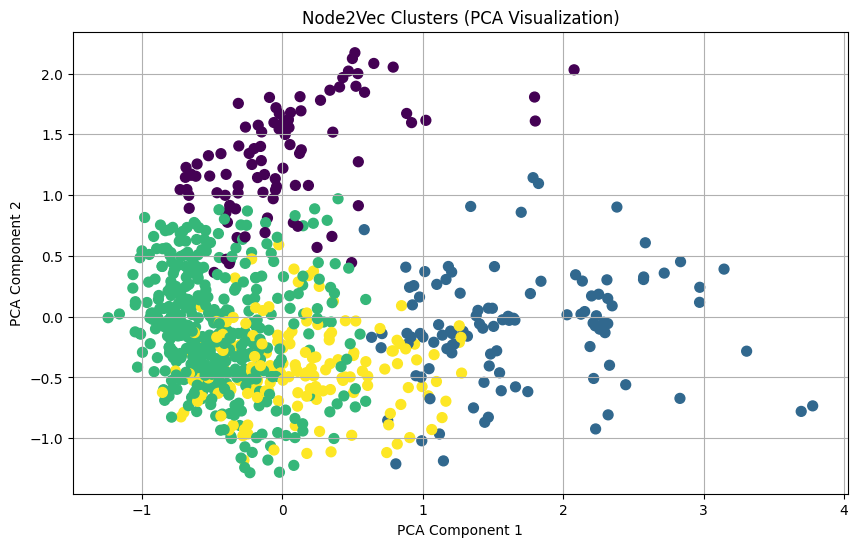

In [22]:




# Step 6: Apply clustering
kmeans = KMeans(n_clusters=4, random_state=42)
clusters = kmeans.fit_predict(embeddings)

# Step 7: Reduce dimensions for visualization
pca = PCA(n_components=2)
reduced_embeddings = pca.fit_transform(embeddings)

# Step 8: Visualize clusters using PCA
plt.figure(figsize=(10, 6))
plt.scatter(reduced_embeddings[:, 0], reduced_embeddings[:, 1], c=clusters, cmap='viridis', s=50)
plt.title("Node2Vec Clusters (PCA Visualization)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.grid(True)
plt.show()
